# Spectroscopy
This notebook is for getting the wavelengths of bands from an input spectrum image, with yapping. Use for understanding, not quick data

In [140]:
# imports
import matplotlib.pyplot as plt
import os
import glob
import numpy as np

import cv2

import tifffile

from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.signal import peak_widths

from pathlib import Path

from PIL import Image

import pandas as pd

from scipy.interpolate import PchipInterpolator

from scipy.ndimage import percentile_filter

from matplotlib.patches import Rectangle

import matplotlib.patheffects as pe

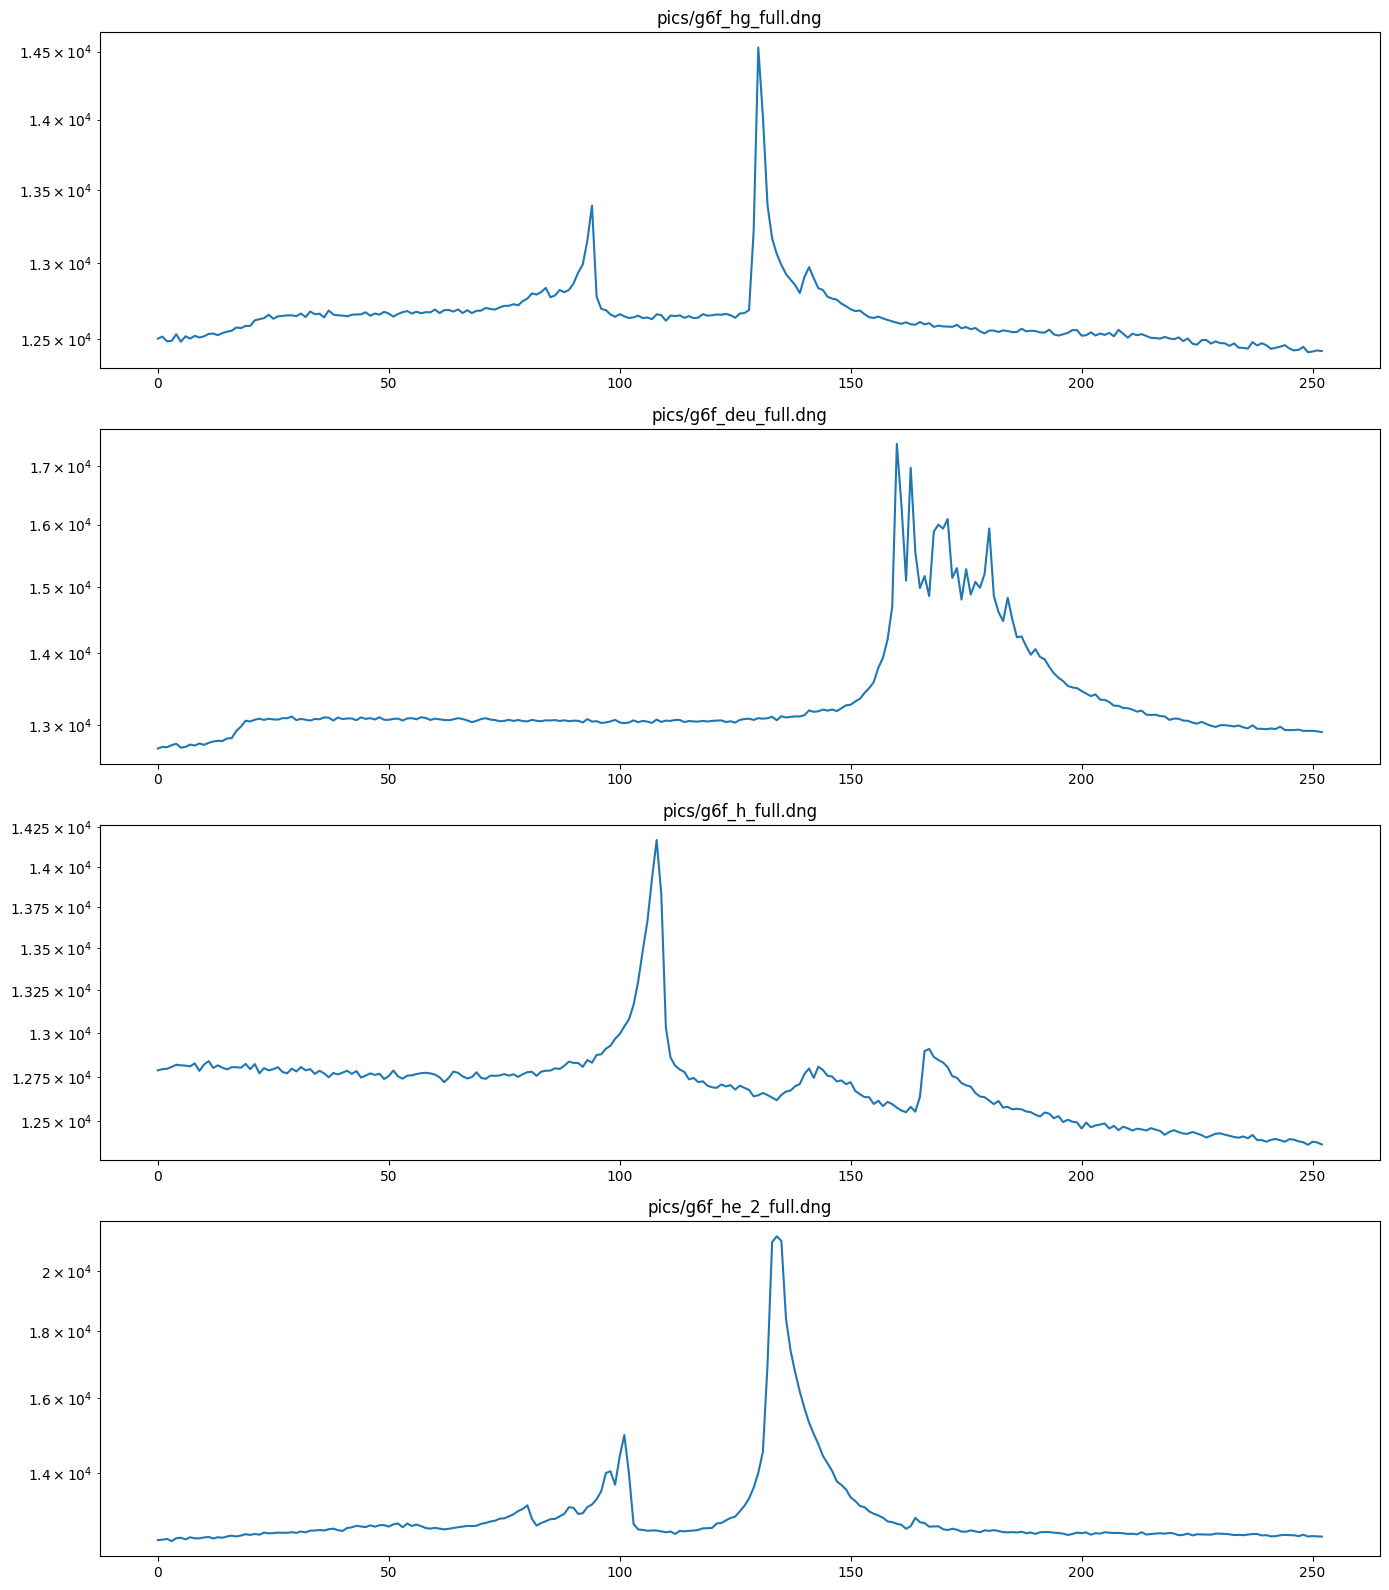

In [141]:
# isolating bands from background
# first do a quick vertical sum to see

picFiles_list = glob.glob(os.path.join("*pics","*"))
counter = 1
total = len(picFiles_list)

fig, axes = plt.subplots(int(total), 1, figsize = (14, 4 * total))

#print(picFiles_list)
for ax, pic in zip(axes.flat, picFiles_list):
    img = cv2.imread(pic)
    h, w, _ = img.shape
    prelim_sum = list(map(lambda x: x[0], np.sum(img, axis = 0)))
    #print(vert_sum)
    # print(np.sum((img), axis = 0))
    # print(len(np.sum((img), axis = 0)))

    ax.plot(range(len(prelim_sum)), prelim_sum)
    ax.set_yscale("log")
    ax.set_title(pic)
    counter += 1

fig.tight_layout()

In [142]:
# we've lost a lot of the faint bands from summing background
# let's fix this by only summing the relavant bands
# also the compression ot preview is doing nasty stuff (WHY is that default????)
# make func to get proper pics and get bands

def get_full_pic(pic):
    with tifffile.TiffFile(pic) as tif:
        img = tif.series[1].asarray()
    return img

print(get_full_pic(picFiles_list[0])[0].shape)

def get_band(pic, band_prop = 5): # where band occupies 1/band_prop of vert area
    #print(f"Image: {pic}")
    img = get_full_pic(pic)
    h, w = img.shape
    #print(img.shape) #(3040, 4056)

    # get brightest 1/5 of image rows next to each other
    row_total_brightness = np.sum(img, axis = 1)
    #print(len(row_total_brightness)) 3040, correct

    cumulative = np.concatenate((
        [0],
        np.cumsum(row_total_brightness)
    ))

    band_size = h // band_prop
    window_sums = (
        cumulative[band_size:] -
        cumulative[:-band_size]
    )

    y_0 = int(np.argmax(window_sums))

    return y_0, y_0 + band_size

(4056,)


[(927, 1535), (869, 1477), (931, 1539), (855, 1463)]


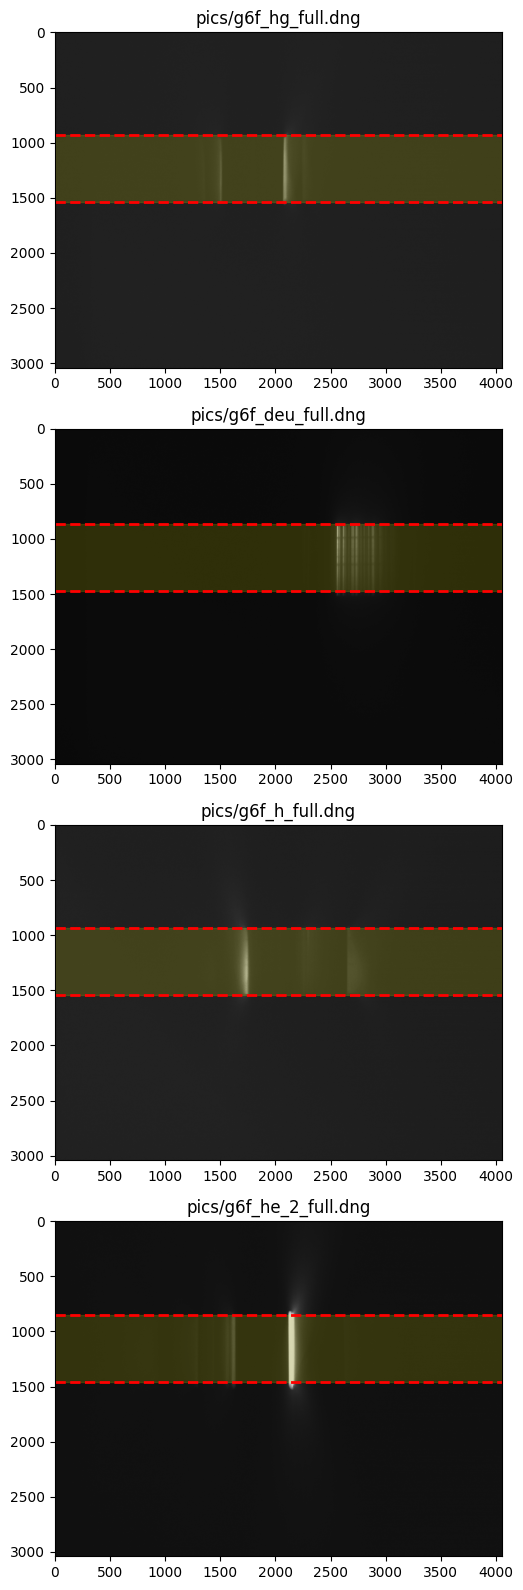

In [143]:
# let's check the bands

regions = []
for pic in picFiles_list:
    regions.append(get_band(pic))

print(regions)

fig, axes = plt.subplots(int(total), 1, figsize = (14, 4 * total))

for ax, pic, (y0, y1) in zip(axes.flat, picFiles_list, regions):

    img = get_full_pic(pic)

    ax.imshow(img, cmap="gray")

    # draw upper and lower boundaries
    ax.axhline(y0, color="red", linestyle="--", linewidth=2)
    ax.axhline(y1, color="red", linestyle="--", linewidth=2)

    # shade the selected region
    ax.axhspan(y0, y1, color="yellow", alpha=0.15)

    ax.set_title(pic)

plt.tight_layout()
plt.show()

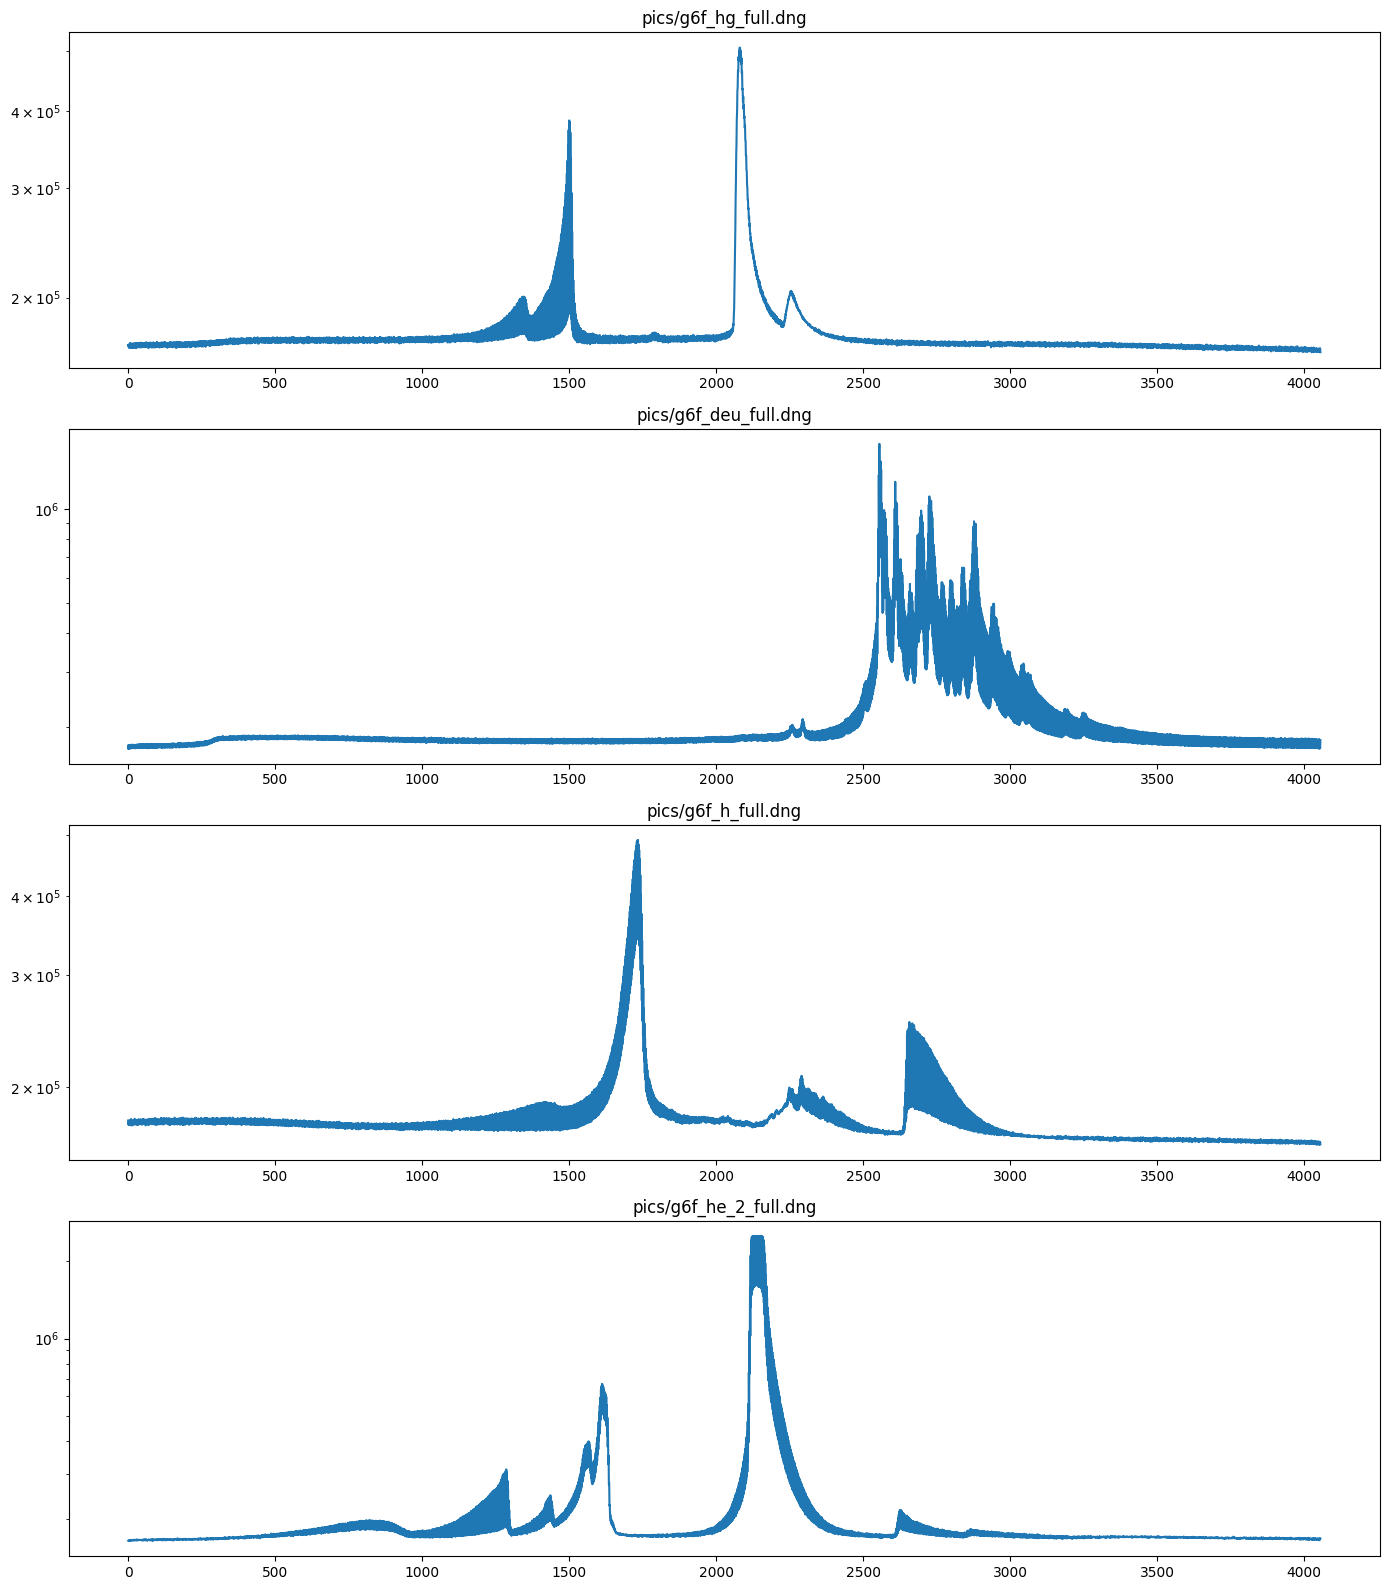

In [144]:
# that looks great!
# let's redo the vertical sum but in only the banded areas

# isolating bands from background
# let's write a proper defintion for vert sum bcos im civilised

def vert_sum(pic, banded = True):
    img = get_full_pic(pic)

    if banded == True:
        start, end = get_band(pic)
    else:
        start, end = 0, len(img)

    img_bands = img[start:end]
    h, w = img_bands.shape
    #print(img_bands)
    #print(vert_sum)
    # print(np.sum((img), axis = 0))
    # print(len(np.sum((img), axis = 0)))
    return np.sum(img_bands, axis=0, dtype=np.float64)

picFiles_list = glob.glob(os.path.join("*pics","*"))
counter = 1
total = len(picFiles_list)

fig, axes = plt.subplots(int(total), 1, figsize = (14, 4 * total))

#print(picFiles_list)
for ax, pic in zip(axes.flat, picFiles_list):
    vert = vert_sum(pic)

    ax.plot(range(len(vert)), vert)
    ax.set_yscale("log")
    ax.set_title(pic)
    counter += 1

fig.tight_layout()

In [145]:
# substantially less noisy. yippee!
# now we pin the peaks to the wavelength of light recorded

# first lets use scipy to get peaks bcos im not coding that
# lots of high-freq noise, due to light flickering and our long exposure times
# hence i shall write a func to smooth the function then get the peaks

def find_peaks_smoothed(sum_lst):
    # Smooth high-frequency noise
    smoothed = gaussian_filter1d(sum_lst, sigma=2)

    peaks, properties = find_peaks(
    smoothed,
    prominence=0.008 * (smoothed.max() - smoothed.min()),
    distance=5)

    return smoothed, peaks

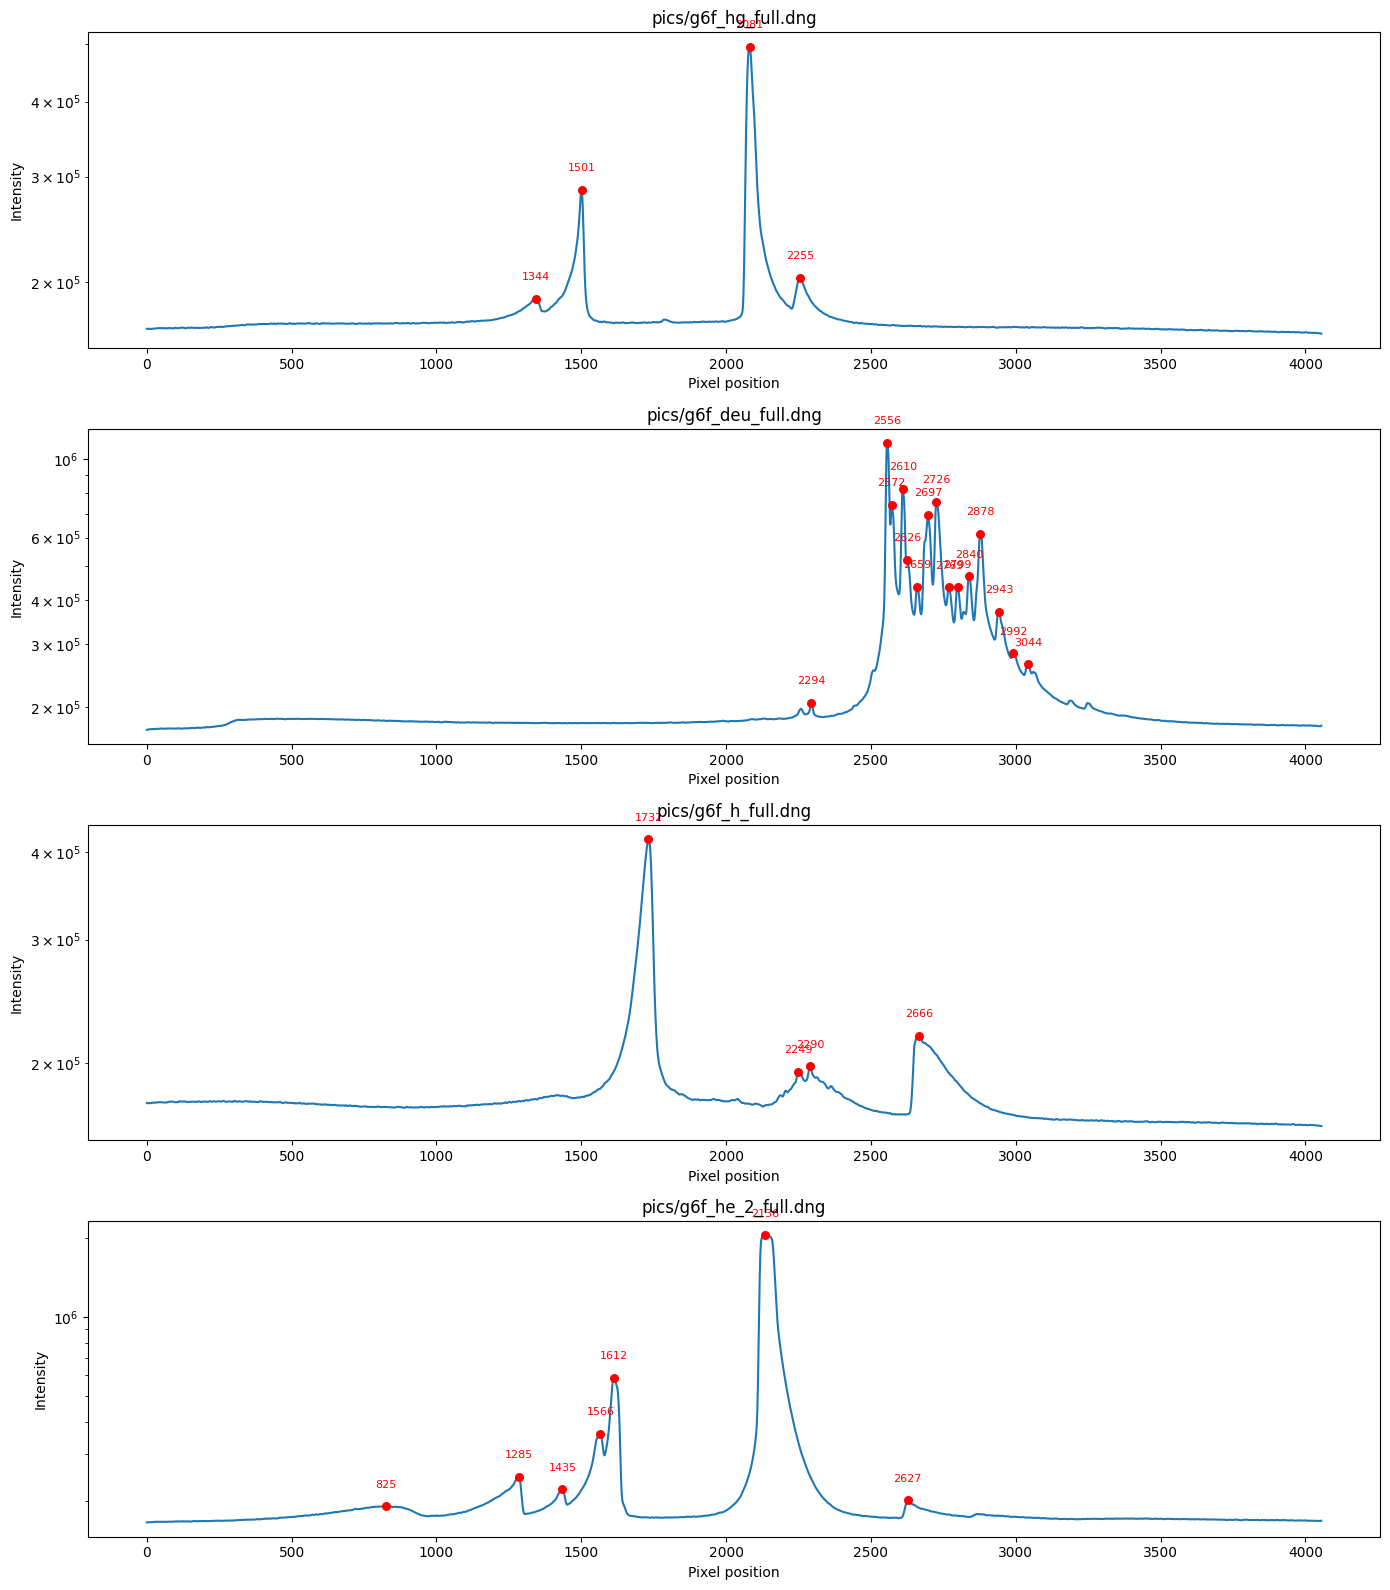

In [146]:
# ok now actually do it

fig, axes = plt.subplots(total, 1, figsize=(14, 4 * total))

for ax, pic in zip(np.atleast_1d(axes).flat, picFiles_list):
    vert = vert_sum(pic)
    smoothed, peaks = find_peaks_smoothed(vert)

    # Plot smoothed spectrum
    ax.plot(smoothed)

    # Red dots on detected peaks
    ax.scatter(
        peaks,
        smoothed[peaks],
        color="red",
        s=30,
        zorder=5
    )

    # Label each peak
    for x in peaks:
        ax.annotate(
            str(x),
            xy=(x, smoothed[x]),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            color="red"
        )

    ax.set_yscale("log")
    ax.set_title(pic)
    ax.set_xlabel("Pixel position")
    ax.set_ylabel("Intensity")

fig.tight_layout()
plt.show()

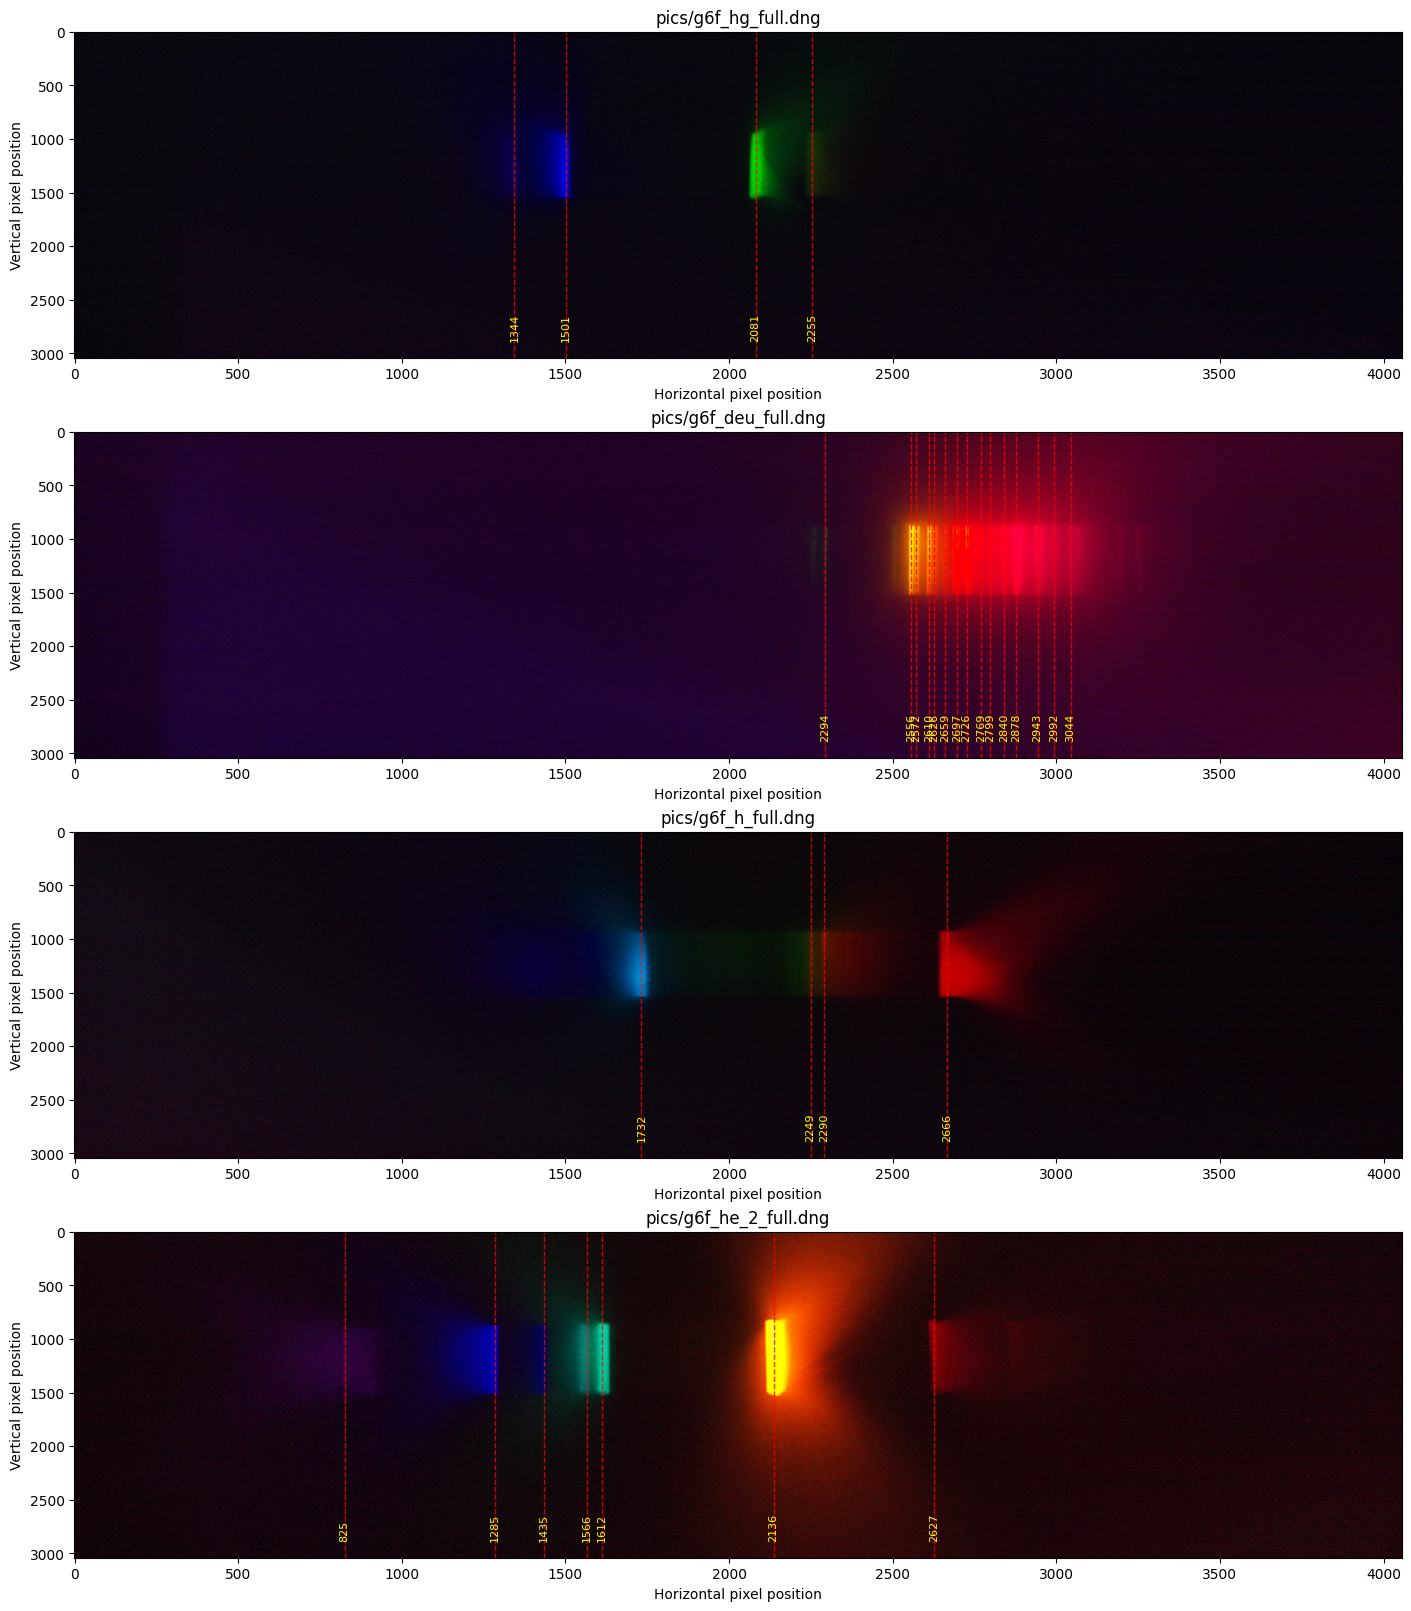

In [147]:
# heck yeah thats beautiful yayyy
# ok now to check if this lines up with img

total = len(picFiles_list)

fig, axes = plt.subplots(
    total, 1,
    figsize=(14, 4 * total),
    constrained_layout=True
)

axes = np.atleast_1d(axes)

for ax, pic in zip(axes, picFiles_list):

    # read full-res RAW image
    with tifffile.TiffFile(pic) as tif:
        img = tif.series[1].asarray()

    # peaks
    vert = vert_sum(pic)
    smoothed, peaks = find_peaks_smoothed(vert)

    # pic is the DNG path from picFiles_list
    jpg_path = Path("pics_jpgs") / (Path(pic).stem + ".jpg")

    if jpg_path.exists():
        # use colour JPEG if available
        img = np.asarray(Image.open(jpg_path).convert("RGB"))
    else:
        # fall back to grayscale RAW
        with tifffile.TiffFile(pic) as tif:
            img = tif.series[1].asarray()

    ax.imshow(img, cmap="gray" if img.ndim == 2 else None, aspect="auto")

    # vertical lines at detected peaks
    for x in peaks:
        ax.axvline(
            x,
            color="red",
            linestyle="--",
            linewidth=1,
            alpha=0.8
        )

        ax.text(
            x, 0.05,
            str(x),
            transform=ax.get_xaxis_transform(),
            color="yellow",
            fontsize=8,
            rotation=90,
            ha="center",
            va="bottom"
        )
    #ax.imshow(img)
    ax.set_title(pic)
    ax.set_xlabel("Horizontal pixel position")
    ax.set_ylabel("Vertical pixel position")

plt.show()


In [148]:
# that is wonderful
# grab wavelength from each spot

# first step: get rgb from each spot

# but to do that we need to deal with bayer blocks

# the bayer pattern is NOT fun to work with
# [b, g, b, g]
# [g, r, g, r]
# [b, g, b, g]
# [g, r, g, r]
# b: both even
# g: one odd one even
# r: both odd

def get_bayer_profiles(pic):
    '''bayer profiles across pic, by horizontal section 
    (only vertical averaging, no horixontal)'''
    img = get_full_pic(pic)
    y0, y1 = get_band(pic)

    # align to complete BGGR Bayer blocks
    y0 = max(0, 2 * (y0 // 2))
    y1 = min(img.shape[0], 2 * (y1 // 2))

    region = img[y0:y1]

    # BGGR:
    # B G
    # G R

    B = region[0::2, 0::2].mean(axis=0)
    G1 = region[0::2, 1::2].mean(axis=0)
    G2 = region[1::2, 0::2].mean(axis=0)
    R = region[1::2, 1::2].mean(axis=0)

    G = (G1 + G2) / 2

    # each Bayer block corresponds to 2 sensor columns
    x = np.arange(len(R)) * 2 + 0.5

    return x, np.column_stack([R, G, B])

In [149]:
# redoing background correction
PERCENTILE = 25
WINDOW = 201
def get_percentile_baseline(pic, 
                            percentile=PERCENTILE, 
                            window=WINDOW):
    x, profiles = get_bayer_profiles(pic)

    baseline = np.column_stack([
        percentile_filter(
            profiles[:, i],
            percentile=percentile,
            size=window,
            mode="nearest"
        )
        for i in range(3)
    ])

    return x, profiles, baseline

def get_rgb_percentile(pic, 
                       percentile=PERCENTILE, 
                       window=WINDOW):

    x, profiles, baseline = get_percentile_baseline(
        pic, percentile, window
    )

    smoothed, peaks = find_peaks_smoothed(
        np.asarray(vert_sum(pic), dtype=float)
    )

    widths, _, _, _ = peak_widths(
        smoothed, peaks, rel_height=0.5
    )

    corrected = profiles - baseline

    records = []

    for peak, width in zip(peaks, widths):

        half = max(4, int(np.ceil(width / 2)))

        # x is in original pixel coordinates
        mask = (
            (x >= peak - half) &
            (x <= peak + half)
        )

        rgb = corrected[mask].mean(axis=0)

        valid = (
            np.all(np.isfinite(rgb))
            and np.all(rgb > 0)
        )

        ratios = (
            rgb / rgb.sum()
            if valid else [np.nan] * 3
        )

        records.append({
            "pixel": int(peak),
            "R": rgb[0],
            "G": rgb[1],
            "B": rgb[2],
            "r": ratios[0],
            "g": ratios[1],
            "b": ratios[2],
            "valid": valid
        })

    return pd.DataFrame(records)

In [150]:
# test if it correctly removes baseline and not the actual peaks

def test_percentile_baseline_removal(pic, 
                                     perc = PERCENTILE,
                                     win = WINDOW):
    x, profiles, baseline = get_percentile_baseline(
        pic, percentile=perc, window=win
    )

    fig, axes = plt.subplots(3, 1, figsize=(14, 9),
                            constrained_layout=True)

    for i, colour in enumerate(["red", "green", "blue"]):
        axes[i].plot(
            x, profiles[:, i],
            color=colour,
            label="RAW profile"
        )

        axes[i].plot(
            x, baseline[:, i],
            "k--",
            label="Estimated background"
        )   

        axes[i].set_title(colour.upper())
        axes[i].set_xlabel("Original pixel position")
        axes[i].set_ylabel("Mean RAW response")
        axes[i].legend()
        axes[i].grid(alpha=0.3)
    plt.suptitle(pic)
    plt.show()

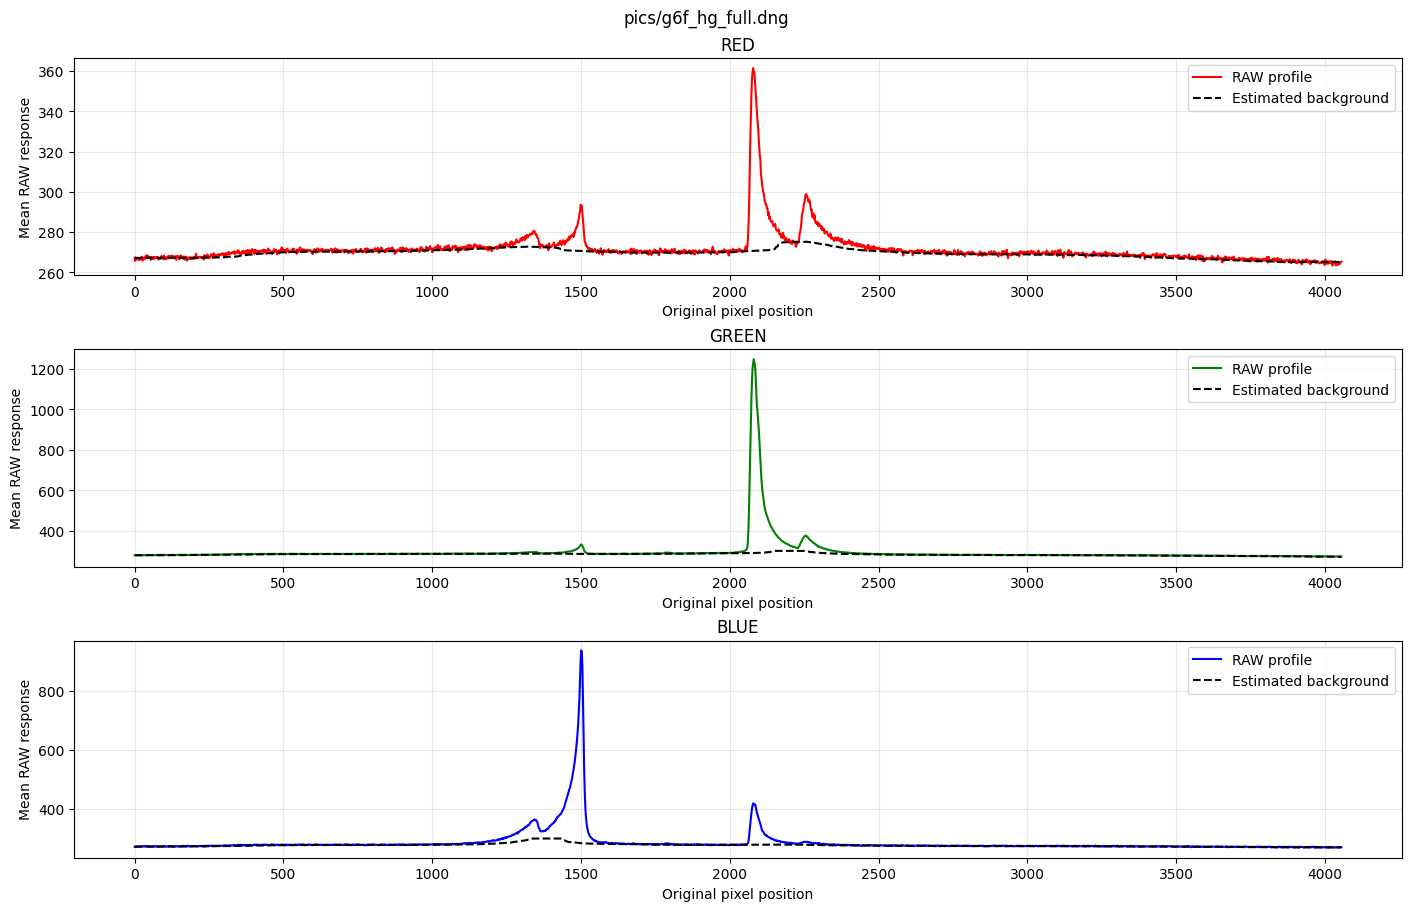

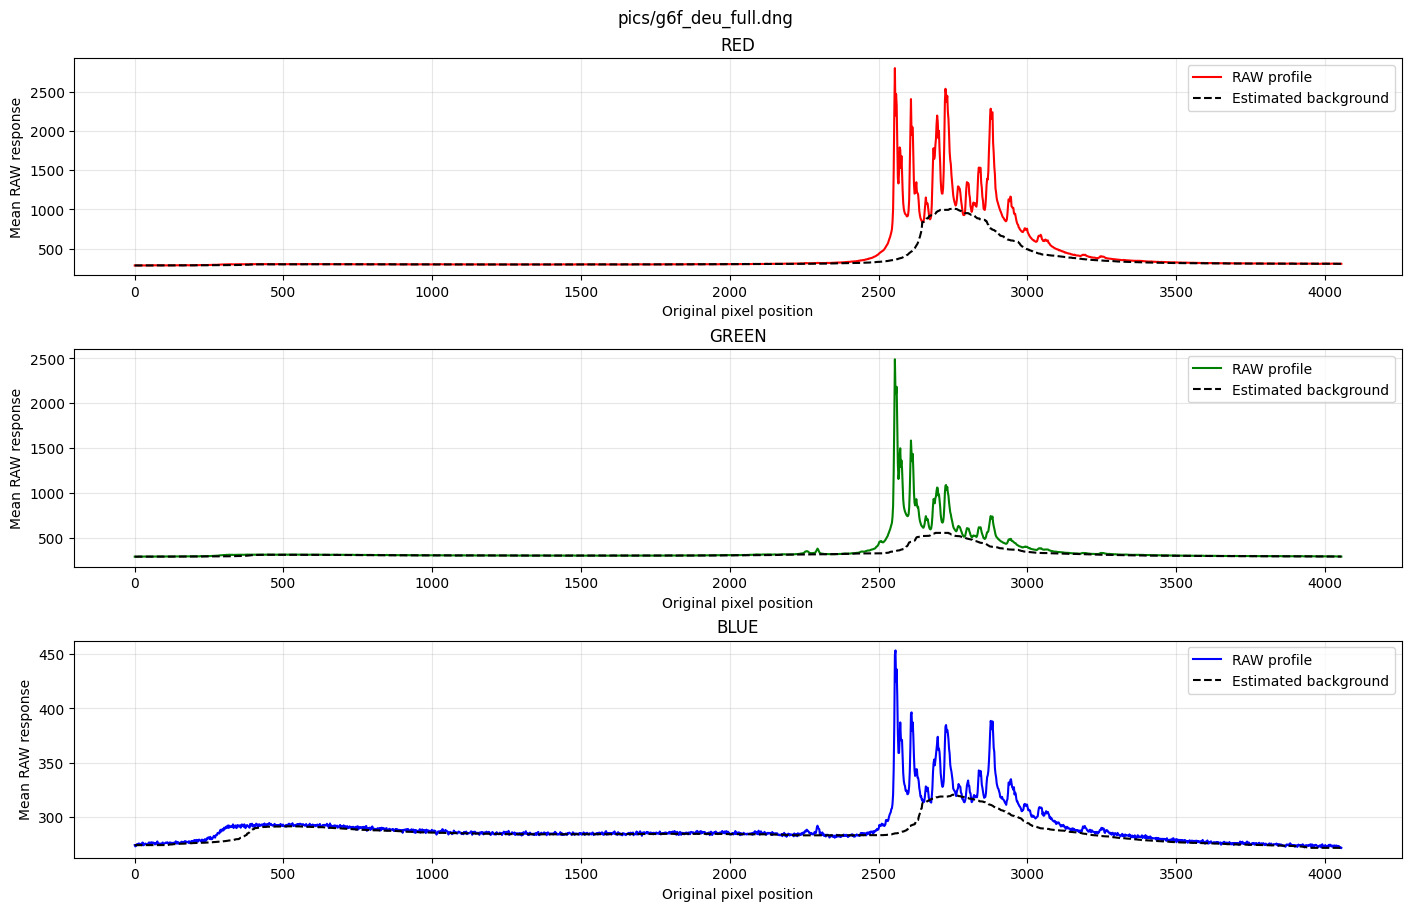

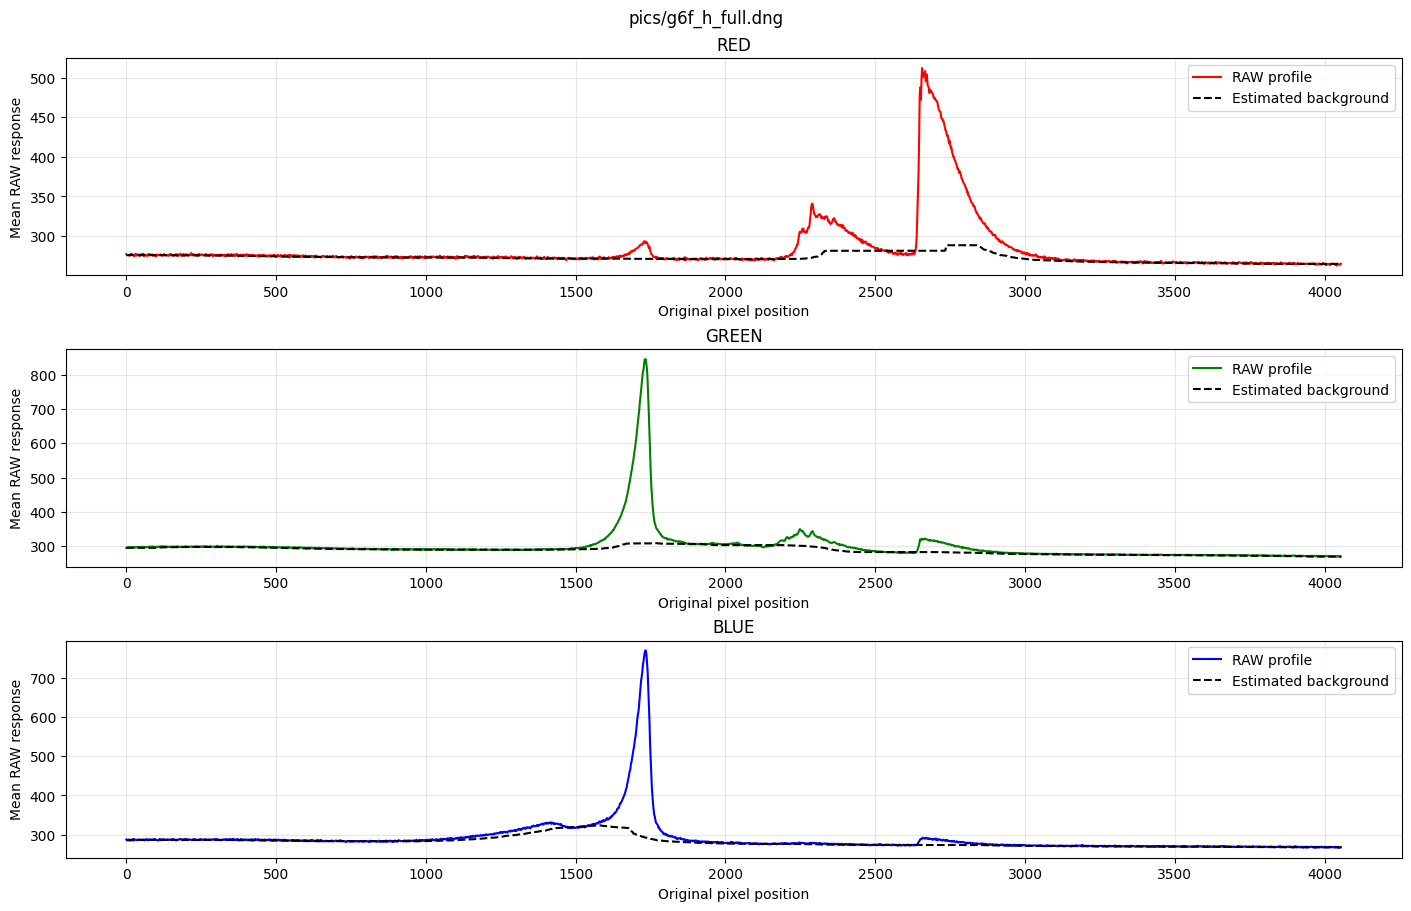

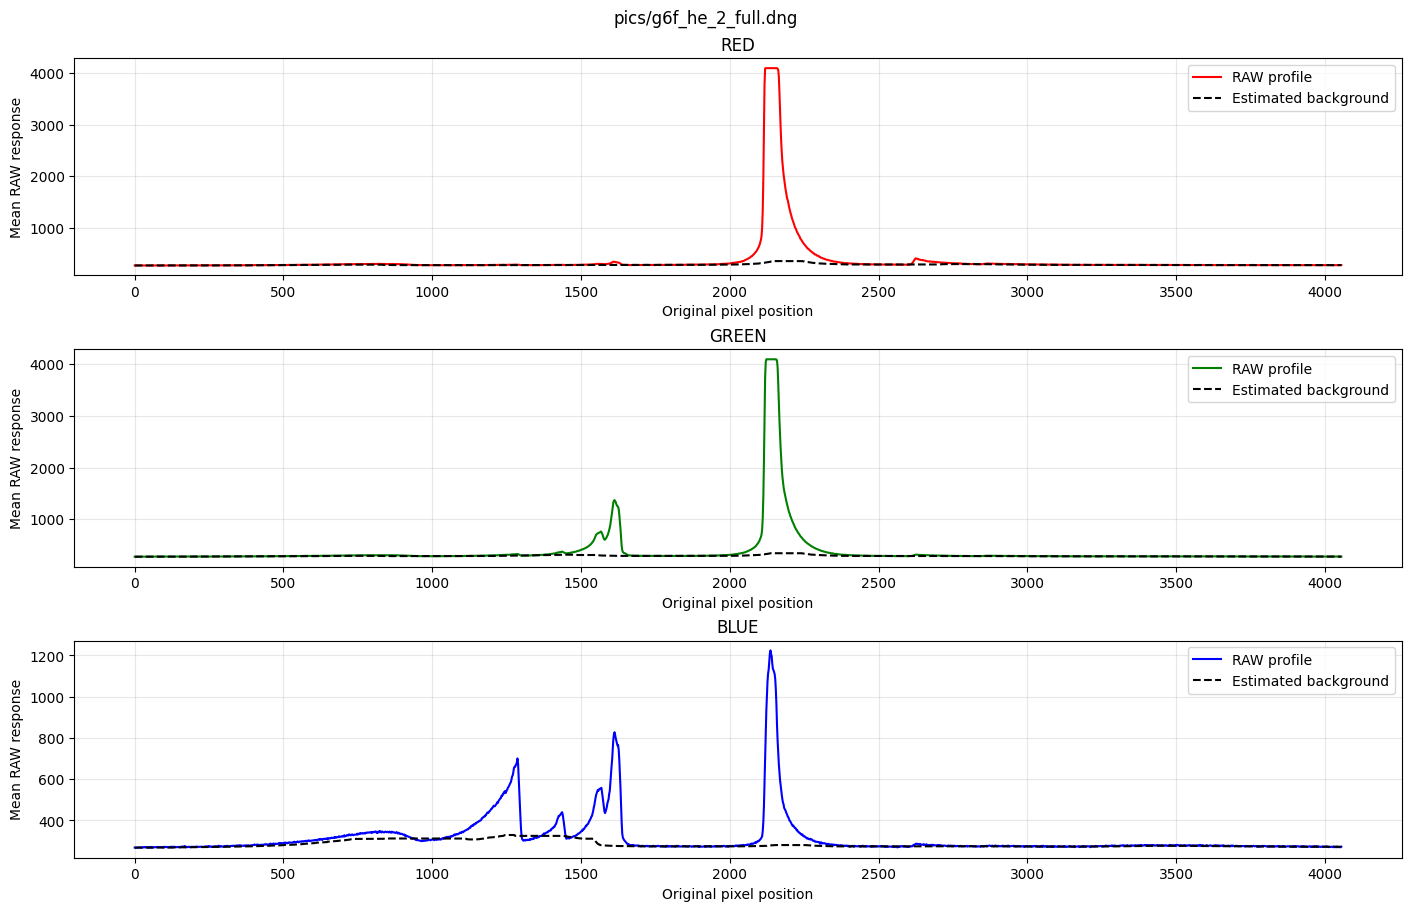

In [151]:
for pic in picFiles_list:
    test_percentile_baseline_removal(pic, 
                                     perc = PERCENTILE, 
                                     win = WINDOW)

In [152]:
# okay great

def get_rgb_nobackground(pic, PERCENTILE = PERCENTILE, WINDOW = WINDOW):
    return get_rgb_percentile(
        pic,
        percentile=PERCENTILE,
        window=WINDOW
    )

In [153]:
# Digitized IMX477 response curve
sensor = pd.read_csv("imx477_response.csv")
sensor = sensor.sort_values("wavelength_nm")

wl = sensor["wavelength_nm"].to_numpy()
responses = sensor[["R", "G", "B"]].to_numpy()

# Interpolate each sensor response
curves = [
    PchipInterpolator(wl, responses[:, i])
    for i in range(3)
]

wl_grid = np.linspace(400, 700, 3000) # visible light

rgb_grid = np.column_stack([
    curve(wl_grid) for curve in curves
])

# Normalize predicted sensor response
rgb_grid = np.clip(rgb_grid, 0, None)
rgb_grid /= rgb_grid.sum(axis=1, keepdims=True)

def predict_sensor_wavelength(data):
    measured = data[["r", "g", "b"]].to_numpy()

    distances = np.linalg.norm(
        measured[:, None, :] - rgb_grid[None, :, :],
        axis=2
    )

    nearest = distances.argmin(axis=1)

    return wl_grid[nearest], distances[
        np.arange(len(nearest)), nearest
    ]


In [154]:
# predictions
# ------- helium --------
print("helium predictions")
helium_bands = { # pixel pos : real wavelength
    825: 388.8,
    1285: 447.1,
    1435: 471.3,
    1566: 492.1,
    1612: 501.5,
    2136: 587.5,
    2627: 667.8
}

he = get_rgb_nobackground("pics/g6f_he_2_full.dng")
he = he[he["valid"]].copy()

he["estimated_nm"], he["colour_distance"] = (
    predict_sensor_wavelength(he)
)

display(he[
    ["pixel", "estimated_nm", "colour_distance"]
].round(2))

# ------- hydrogen -------
# pixel pos:legit
hydrogen_lines = {
    1732: 486,
    2666: 656 
}

print("hydrogen predictions")
h = get_rgb_nobackground("pics/g6f_h_full.dng")
h = h[h["valid"]].copy()

h["estimated_nm"], h["colour_distance"] = (
    predict_sensor_wavelength(h)
)

display(h[
    ["pixel", "estimated_nm", "colour_distance"]
].round(2))

# ------- mercury --------
mercury_lines = {
    1344: 404.7,
    1501: 435.8,
    2081: 546.1,
    2255: 576.9 # there's another at 579 which we can't resolve
}
print("mercury predicitons")
hg = get_rgb_nobackground("pics/g6f_hg_full.dng")
hg = hg[hg["valid"]].copy()

hg["estimated_nm"], hg["colour_distance"] = (
    predict_sensor_wavelength(hg)
)

display(hg[
    ["pixel", "estimated_nm", "colour_distance"]
].round(2))



helium predictions


,pixel,estimated_nm,colour_distance
0,825,400.00,0.23
1,1285,458.22,0.00
2,1435,478.33,0.01
3,1566,500.83,0.02
4,1612,506.14,0.01
5,2136,591.16,0.06
6,2627,662.19,0.02


hydrogen predictions


,pixel,estimated_nm,colour_distance
0,1732,491.23,0.01
1,2249,586.76,0.01
2,2290,594.26,0.01
3,2666,654.08,0.05


mercury predicitons


,pixel,estimated_nm,colour_distance
0,1344,422.61,0.00
1,1501,439.01,0.00
2,2081,543.25,0.00
3,2255,576.86,0.04


ACCURACY SUMMARY


,Element,Lines,MAE (nm),RMSE (nm),Max error (nm),Mean % error
0,Helium,6,6.798,7.254,11.119,1.357
1,Hydrogen,2,3.573,3.939,5.230,0.684
2,Mercury,4,6.003,9.208,17.908,1.423
3,OVERALL,12,5.996,7.560,17.908,1.267


INDIVIDUAL LINE ERRORS


,element,pixel,actual_nm,estimated_nm,error_nm,percent_error
0,Helium,1285,447.1,458.219,11.119,2.487
1,Helium,1435,471.3,478.326,7.026,1.491
2,Helium,1566,492.1,500.834,8.734,1.775
3,Helium,1612,501.5,506.135,4.635,0.924
4,Helium,2136,587.5,591.164,3.664,0.624
5,Helium,2627,667.8,662.187,-5.613,0.840
6,Hydrogen,1732,486.0,491.230,5.230,1.076
7,Hydrogen,2666,656.0,654.085,-1.915,0.292
8,Mercury,1344,404.7,422.608,17.908,4.425
9,Mercury,1501,435.8,439.013,3.213,0.737


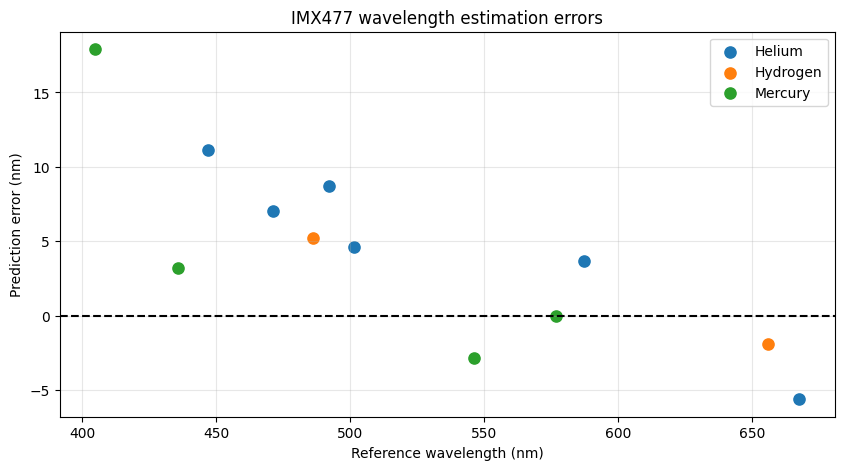

In [155]:
datasets = {
    "Helium": (he, helium_bands),
    "Hydrogen": (h, hydrogen_lines),
    "Mercury": (hg, mercury_lines)
}

results = []
summary = []

for element, (data, references) in datasets.items():

    df = data.copy()

    # match detected peaks to known wavelengths
    df["actual_nm"] = df["pixel"].map(references)
    df = df.dropna(subset=["actual_nm", "estimated_nm"])

    # exclude wavelengths outside calibration range
    df = df[
        df["actual_nm"].between(wl_grid.min(), wl_grid.max())
    ].copy()

    # calculate errors
    df["error_nm"] = df["estimated_nm"] - df["actual_nm"]
    df["abs_error_nm"] = df["error_nm"].abs()
    df["percent_error"] = (
        100 * df["abs_error_nm"] / df["actual_nm"]
    )

    df["element"] = element
    results.append(df)

    if len(df) == 0:
        continue

    summary.append({
        "Element": element,
        "Lines": len(df),
        "MAE (nm)": df["abs_error_nm"].mean(),
        "RMSE (nm)": np.sqrt(np.mean(df["error_nm"]**2)),
        "Max error (nm)": df["abs_error_nm"].max(),
        "Mean % error": df["percent_error"].mean()
    })

# combine results
all_results = pd.concat(results, ignore_index=True)

# overall statistics
summary.append({
    "Element": "OVERALL",
    "Lines": len(all_results),
    "MAE (nm)": all_results["abs_error_nm"].mean(),
    "RMSE (nm)": np.sqrt(np.mean(all_results["error_nm"]**2)),
    "Max error (nm)": all_results["abs_error_nm"].max(),
    "Mean % error": all_results["percent_error"].mean()
})

summary_df = pd.DataFrame(summary)

print("ACCURACY SUMMARY")
display(summary_df.round(3))

print("INDIVIDUAL LINE ERRORS")
display(all_results[
    ["element", "pixel", "actual_nm",
     "estimated_nm", "error_nm", "percent_error"]
].round(3))

# plot errors
fig, ax = plt.subplots(figsize=(10, 5))

for element, group in all_results.groupby("element"):
    ax.scatter(
        group["actual_nm"],
        group["error_nm"],
        s=65,
        label=element
    )

ax.axhline(0, color="black", linestyle="--")

ax.set_xlabel("Reference wavelength (nm)")
ax.set_ylabel("Prediction error (nm)")
ax.set_title("IMX477 wavelength estimation errors")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


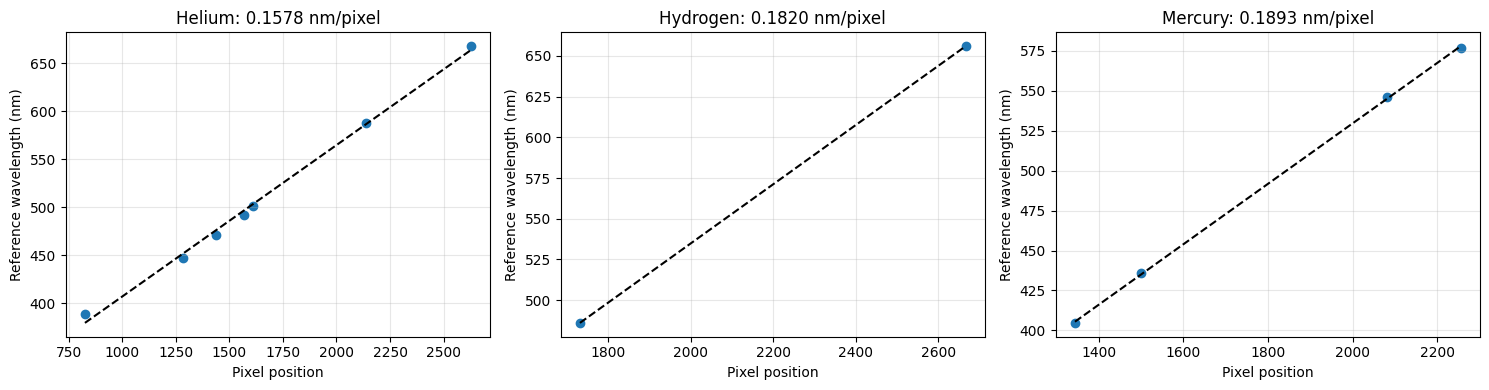

In [156]:
# getting better rectangle widths
datasets = {
    "Helium": (he, helium_bands),
    "Hydrogen": (h, hydrogen_lines),
    "Mercury": (hg, mercury_lines)
}

dispersion = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (element, (data, refs)) in zip(axes, datasets.items()):
    matched = data.copy()
    matched["actual_nm"] = matched["pixel"].map(refs)
    matched = matched.dropna(subset=["actual_nm"])

    x = matched["pixel"].to_numpy()
    y = matched["actual_nm"].to_numpy()

    slope, intercept = np.polyfit(x, y, 1)

    dispersion[element] = abs(slope)

    ax.scatter(x, y)
    ax.plot(x, slope*x + intercept, "k--")

    ax.set_title(
        f"{element}: {abs(slope):.4f} nm/pixel"
    )
    ax.set_xlabel("Pixel position")
    ax.set_ylabel("Reference wavelength (nm)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

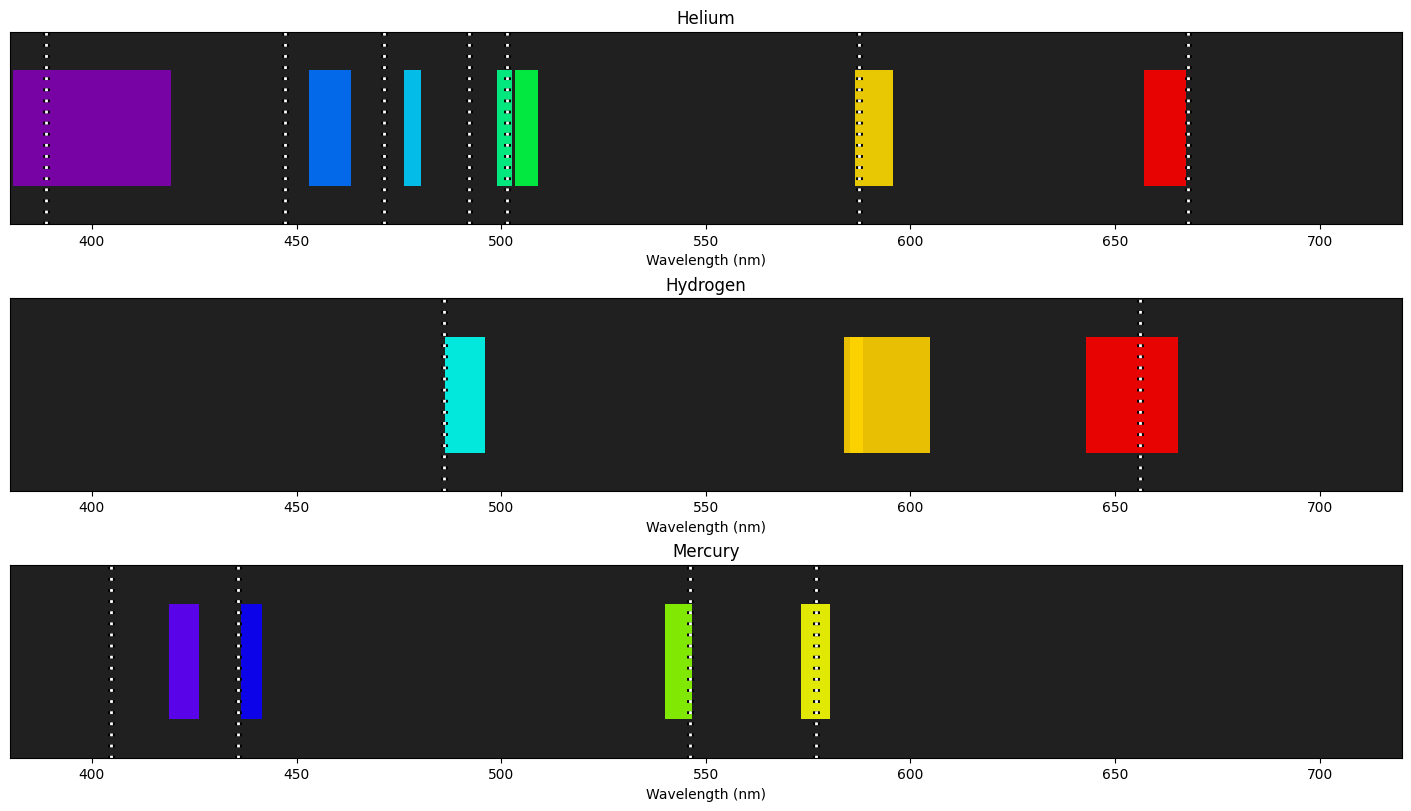

In [157]:
# colourssss

datasets = {
    "Helium": ("pics/g6f_he_2_full.dng", he, helium_bands),
    "Hydrogen": ("pics/g6f_h_full.dng", h, hydrogen_lines),
    "Mercury": ("pics/g6f_hg_full.dng", hg, mercury_lines)
}

# make wavelength colours matplotlib comparable
def wavelength_to_rgb(wavelength):
    """Approximate visible wavelength (nm) to display RGB."""

    w = float(wavelength)

    if not 380 <= w <= 780:
        return (0.0, 0.0, 0.0)

    if w < 440:
        r, g, b = -(w-440)/(440-380), 0, 1
    elif w < 490:
        r, g, b = 0, (w-440)/(490-440), 1
    elif w < 510:
        r, g, b = 0, 1, -(w-510)/(510-490)
    elif w < 580:
        r, g, b = (w-510)/(580-510), 1, 0
    elif w < 645:
        r, g, b = 1, -(w-645)/(645-580), 0
    else:
        r, g, b = 1, 0, 0

    # Reduce brightness near visible-spectrum boundaries
    if w < 420:
        factor = 0.3 + 0.7*(w-380)/(420-380)
    elif w > 700:
        factor = 0.3 + 0.7*(780-w)/(780-700)
    else:
        factor = 1.0

    gamma = 0.8

    return tuple(
        (max(0, c) * factor)**gamma
        for c in (r, g, b)
    )

# Approximate display conversion, not a calibrated linewidth
nm_per_pixel = 0.15

fig, axes = plt.subplots(
    3, 1, figsize=(14, 8),
    constrained_layout=True
)

for ax, (element, (pic, data, references)) in zip(
    axes, datasets.items()
):
    # Get peak widths from RAW intensity profile
    profile = np.asarray(vert_sum(pic), dtype=float)
    smoothed, peaks = find_peaks_smoothed(profile)

    widths, _, _, _ = peak_widths(
        smoothed, peaks, rel_height=0.5
    )

    width_map = dict(zip(peaks.astype(int), widths))



    y0, y1 = get_band(pic)

    for _, row in data.iterrows():
        x = int(row["pixel"])
        wavelength = float(row["estimated_nm"])

        # Measured width in pixels -> approximate nm
        width_px = width_map.get(x, 10)
        width_nm = width_px * dispersion[element]

        # colour
        rgb = wavelength_to_rgb(wavelength)

        # Solid coloured measured band
        rect = Rectangle(
            (wavelength - width_nm/2, 0),
            width_nm,
            1,
            facecolor=rgb,
            edgecolor="none",
            alpha=0.9
        )

        ax.add_patch(rect)
        rect.set_y(0.2)
        rect.set_height(0.6)

    # theoretical reference lines as dotted vertical markers
    for actual_nm in references.values():
        line = ax.axvline(
            actual_nm,
            color="white",
            linestyle=(0, (1, 3)),
            linewidth=2,
            ymin=0,
            ymax=1
        )
        line.set_path_effects([
            pe.Stroke(linewidth=5, foreground="black"),
            pe.Normal()])


    ax.set_xlim(380, 720)
    ax.set_ylim(0, 1)
    ax.set_facecolor("#202020")
    ax.set_yticks([])
    ax.set_xlabel("Wavelength (nm)")
    ax.set_title(element)
    ax.grid(False)

plt.show()



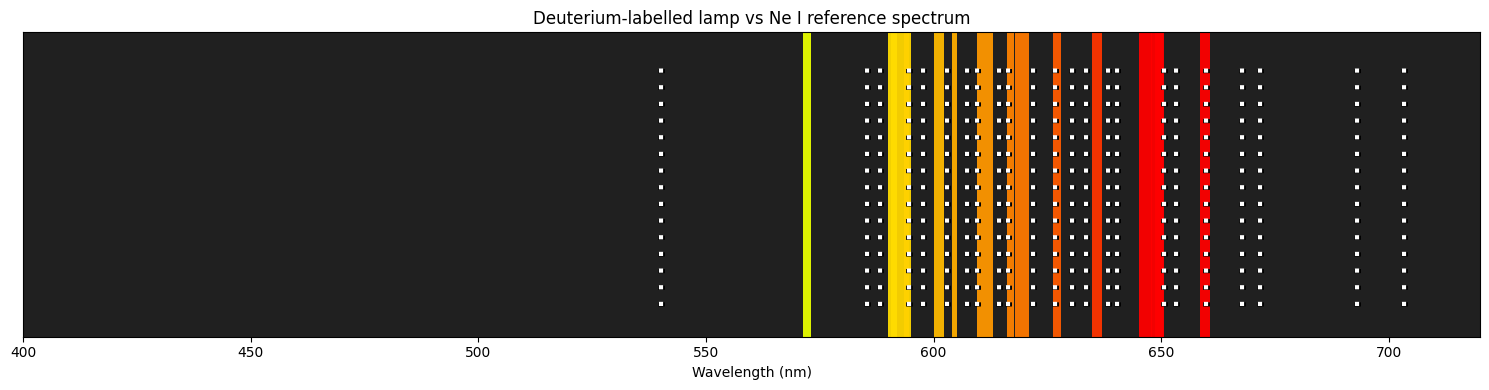

,pixel,estimated_nm,colour_distance
0,2294,572.157,0.033
1,2556,592.764,0.005
2,2572,594.065,0.002
3,2610,601.167,0.001
4,2626,604.568,0.005
5,2659,590.964,0.023
6,2697,611.270,0.003
7,2726,619.473,0.004
8,2769,616.872,0.012
9,2799,627.076,0.015


In [158]:
# sus.

pic = "pics/g6f_deu_full.dng"

# Prominent Ne I reference wavelengths (nm)
neon_reference_nm = [
    540.06, 585.25, 588.19, 594.48, 597.55,
    603.00, 607.43, 609.62, 614.31, 616.36,
    621.73, 626.65, 630.48, 633.44, 638.30,
    640.22, 650.65, 653.29, 659.90, 667.83,
    671.70, 692.95, 703.24
]

# Extract measured RGB and predict wavelengths
deu = get_rgb_nobackground(pic)
deu = deu[deu["valid"]].copy()

deu["estimated_nm"], deu["colour_distance"] = (
    predict_sensor_wavelength(deu)
)

# Get peak widths from RAW profile
profile = np.asarray(vert_sum(pic), dtype=float)
smoothed, peaks = find_peaks_smoothed(profile)

widths, _, _, _ = peak_widths(
    smoothed, peaks, rel_height=0.5
)

width_map = dict(zip(peaks.astype(int), widths))

# Same approximate display-width conversion as before
nm_per_pixel = 0.15

fig, ax = plt.subplots(figsize=(15, 4))

# Measured bands
for _, row in deu.iterrows():
    x = int(row["pixel"])
    wavelength = float(row["estimated_nm"])

    width_px = width_map.get(x, 10)
    width_nm = max(1, width_px * nm_per_pixel)

    rgb = wavelength_to_rgb(wavelength)

    ax.add_patch(Rectangle(
        (wavelength - width_nm/2, 0),
        width_nm,
        1,
        facecolor=rgb,
        edgecolor="none",
        alpha=0.95,
        zorder=2
    ))

# Neon reference lines: white dots with black outline
for actual_nm in neon_reference_nm:
    line = ax.axvline(
        actual_nm,
        color="white",
        linestyle=(0, (1, 3)),
        linewidth=3,
        ymin=0.1,
        ymax=0.9,
        zorder=10
    )

    line.set_path_effects([
        pe.Stroke(linewidth=5, foreground="black"),
        pe.Normal()
    ])

ax.set_xlim(400, 720)
ax.set_ylim(0, 1)
ax.set_facecolor("#202020")
ax.set_yticks([])
ax.set_xlabel("Wavelength (nm)")
ax.set_title("Deuterium-labelled lamp vs Ne I reference spectrum")
ax.grid(False)

plt.tight_layout()
plt.show()

display(
    deu[["pixel", "estimated_nm", "colour_distance"]]
    .round(3)
)


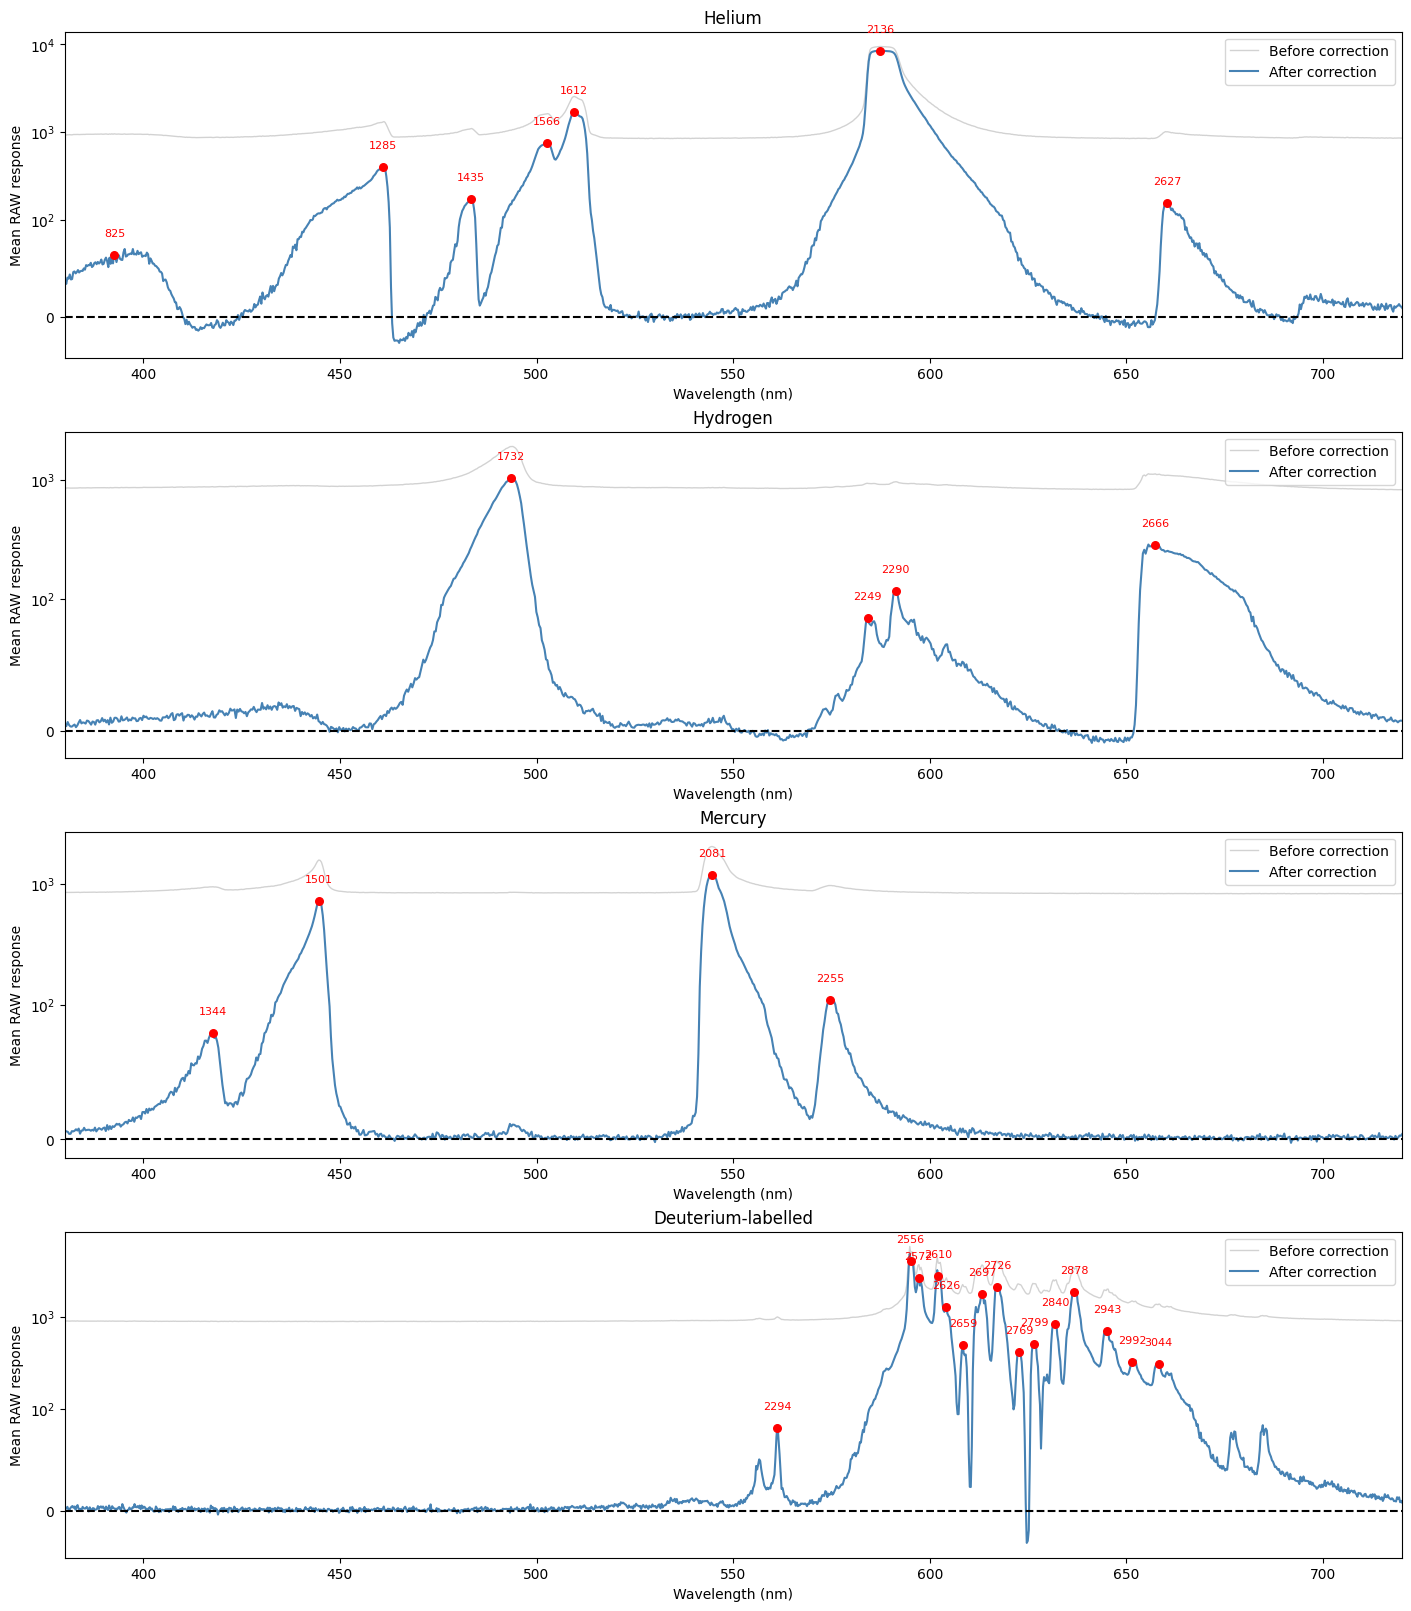

In [159]:
datasets = {
    "Helium": (
        "pics/g6f_he_2_full.dng",
        he,
        [388.8, 447.1, 471.3, 492.1, 501.5, 587.5, 667.8, 706.5]
    ),
    "Hydrogen": (
        "pics/g6f_h_full.dng",
        h,
        [410.17, 434.05, 486.13, 656.28]
    ),
    "Mercury": (
        "pics/g6f_hg_full.dng",
        hg,
        [404.66, 435.83, 546.07, 576.96, 579.07]
    ),
    "Deuterium-labelled": (
        "pics/g6f_deu_full.dng",
        deu,
        neon_reference_nm
    )
}

fig, axes = plt.subplots(
    len(datasets), 1,
    figsize=(14, 4 * len(datasets)),
    constrained_layout=True
)

for ax, (element, (pic, data, refs)) in zip(
    np.atleast_1d(axes).flat, datasets.items()
):

    # Original peak positions (full-resolution pixels)
    profile = np.asarray(vert_sum(pic), dtype=float)
    smoothed, peaks = find_peaks_smoothed(profile)

    # Get Bayer RGB profiles and percentile background
    x, profiles, baseline = get_percentile_baseline(
        pic,
        percentile=PERCENTILE,
        window=WINDOW
    )

    # Corrected intensity (do not clip negative values)
    corrected = profiles - baseline

    raw_intensity = profiles.sum(axis=1)
    corrected_intensity = corrected.sum(axis=1)

    # Fit pixel -> wavelength using RGB-estimated peaks
    valid = data.dropna(
        subset=["pixel", "estimated_nm"]
    ).sort_values("pixel")

    x_cal = valid["pixel"].to_numpy()
    wl_cal = valid["estimated_nm"].to_numpy()

    slope, intercept = np.polyfit(x_cal, wl_cal, 1)

    # Convert Bayer-profile positions into wavelength
    wavelength_axis = slope * x + intercept

    # Interpolate corrected intensity at detected peak positions
    peak_intensity = np.interp(
        peaks, x, corrected_intensity
    )

    peak_wavelengths = slope * peaks + intercept

    # Uncorrected spectrum (faint grey)
    ax.plot(
        wavelength_axis,
        raw_intensity,
        color="grey",
        alpha=0.35,
        linewidth=1,
        label="Before correction"
    )

    # Corrected spectrum
    ax.plot(
        wavelength_axis,
        corrected_intensity,
        color="steelblue",
        linewidth=1.5,
        label="After correction"
    )

    # Detected peaks
    ax.scatter(
        peak_wavelengths,
        peak_intensity,
        color="red",
        s=30,
        zorder=5
    )

    # Label original pixel positions
    for px, wl, intensity in zip(
        peaks, peak_wavelengths, peak_intensity
    ):
        ax.annotate(
            str(int(px)),
            xy=(wl, intensity),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            color="red"
        )

    # Theoretical emission lines
    # Actually we can't do this any more as the official calibration curve isn't
    # linear
    # so the theoretical lines will always be off on this plot
    # for ref in refs:
    #     ax.axvline(
    #         ref,
    #         color="black",
    #         linestyle=":",
    #         linewidth=1.5,
    #         alpha=0.7,
    #         zorder=3
    #     )

    # Symmetric logarithmic scale includes zero
    ax.set_yscale("symlog", linthresh=100)

    # Zero baseline
    ax.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=1.5,
        zorder=10
    )

    ax.set_xlim(380, 720)
    ax.set_title(element)
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Mean RAW response")
    ax.grid(False)
    ax.legend(loc="upper right")

plt.show()


In [160]:

datasets = {
    "Helium": ("pics/g6f_he_2_full.dng", helium_bands),
    "Hydrogen": ("pics/g6f_h_full.dng", hydrogen_lines),
    "Mercury": ("pics/g6f_hg_full.dng", mercury_lines)
}

records = []

for element, (pic, refs) in datasets.items():

    methods = {
        "Local background": get_rgb_nobackground(pic),
        "Percentile baseline": get_rgb_percentile(pic)
    }

    for method, data in methods.items():
        valid = data[data["valid"]].copy()

        if valid.empty:
            continue

        valid["estimated_nm"], valid["colour_distance"] = (
            predict_sensor_wavelength(valid)
        )

        valid["actual_nm"] = valid["pixel"].map(refs)

        valid = valid.dropna(subset=["actual_nm"])
        valid = valid[
            valid["actual_nm"].between(
                wl_grid.min(), wl_grid.max()
            )
        ]

        for _, row in valid.iterrows():
            records.append({
                "element": element,
                "pixel": int(row["pixel"]),
                "method": method,
                "actual_nm": row["actual_nm"],
                "estimated_nm": row["estimated_nm"],
                "error_nm": row["estimated_nm"] - row["actual_nm"],
                "colour_distance": row["colour_distance"]
            })

comparison = pd.DataFrame(records)

# Only compare lines valid under both methods
counts = comparison.groupby(
    ["element", "pixel"]
)["method"].nunique()

common = counts[counts == 2].index

fair = comparison.set_index(
    ["element", "pixel"]
).loc[common].reset_index()

summary = fair.groupby(
    ["element", "method"]
).agg(
    lines=("pixel", "count"),
    MAE_nm=("error_nm", lambda x: np.mean(np.abs(x))),
    RMSE_nm=("error_nm", lambda x: np.sqrt(np.mean(x**2)))
).reset_index()

display(summary.round(3))


,element,method,lines,MAE_nm,RMSE_nm
0,Helium,Local background,6,6.798,7.254
1,Helium,Percentile baseline,6,6.798,7.254
2,Hydrogen,Local background,2,3.573,3.939
3,Hydrogen,Percentile baseline,2,3.573,3.939
4,Mercury,Local background,4,6.003,9.208
5,Mercury,Percentile baseline,4,6.003,9.208


In [161]:
settings = [
    (25, 51),
    (25, 61),
    (25, 71),
    (30, 51),
    (30, 61),
    (30, 71),
    (35, 51),
    (35, 61),
    (35, 71)
]

records = []

for percentile, window in settings:

    for element, (pic, refs) in datasets.items():

        data = get_rgb_percentile(
            pic, percentile=percentile, window=window
        )

        data = data[data["valid"]].copy()

        if data.empty:
            continue

        data["estimated_nm"], _ = (
            predict_sensor_wavelength(data)
        )

        data["actual_nm"] = data["pixel"].map(refs)

        data = data.dropna(subset=["actual_nm"])
        data = data[
            data["actual_nm"].between(
                wl_grid.min(), wl_grid.max()
            )
        ]

        for _, row in data.iterrows():
            records.append({
                "percentile": percentile,
                "window": window,
                "element": element,
                "pixel": int(row["pixel"]),
                "error_nm": row["estimated_nm"] - row["actual_nm"]
            })

sweep = pd.DataFrame(records)

summary = sweep.groupby(
    ["percentile", "window", "element"]
).agg(
    lines=("pixel", "count"),
    MAE_nm=("error_nm", lambda x: np.mean(np.abs(x)))
).reset_index()

display(summary.round(3))


,percentile,window,element,lines,MAE_nm
0,25,51,Helium,6,4.223
1,25,51,Hydrogen,2,3.473
2,25,51,Mercury,4,3.257
3,25,61,Helium,6,2.956
4,25,61,Hydrogen,2,3.523
5,25,61,Mercury,4,3.282
6,25,71,Helium,6,3.414
7,25,71,Hydrogen,2,3.573
8,25,71,Mercury,4,3.632
9,30,51,Helium,6,3.723


## error stuff

In [162]:

import numpy as np
import pandas as pd
from scipy.signal import peak_widths

# Same settings as spectroscopy_reasoned
PERCENTILE = 25
WINDOW = 61
N_SIMULATIONS = 5000

rng = np.random.default_rng(42)

def wavelength_uncertainty(pic):

    # Get background-corrected Bayer RGB profiles
    x, profiles, baseline = get_percentile_baseline(
        pic, percentile=PERCENTILE, window=WINDOW
    )
    corrected = profiles - baseline

    # Detect peaks BEFORE background subtraction
    raw_profile = np.asarray(vert_sum(pic), dtype=float)
    smoothed, peaks = find_peaks_smoothed(raw_profile)

    # Measure widths using the original intensity profile
    widths, _, _, _ = peak_widths(
        smoothed, peaks, rel_height=0.5
    )

    results = []

    for peak, width in zip(peaks, widths):

        half = max(4, int(np.ceil(width / 2)))
        mask = (x >= peak - half) & (x <= peak + half)

        samples = corrected[mask]
        N = len(samples)

        if N < 4:
            continue

        # Mean RGB across the detected band
        mean_rgb = samples.mean(axis=0)

        # Must be positive to normalize meaningfully
        if not np.all(np.isfinite(mean_rgb)) or np.any(mean_rgb <= 0):
            continue

        # Covariance of RGB samples
        covariance = np.cov(samples, rowvar=False)

        # Covariance of the mean (independent-sample assumption)
        covariance_mean = covariance / N

        # Standard errors of mean R, G, B
        rgb_errors = np.sqrt(np.diag(covariance_mean))

        # Monte Carlo simulation
        simulated_rgb = rng.multivariate_normal(
            mean_rgb,
            covariance_mean,
            size=N_SIMULATIONS
        )

        # Exclude nonphysical simulated RGB values
        simulated_rgb = simulated_rgb[
            np.all(simulated_rgb > 0, axis=1)
        ]

        if len(simulated_rgb) < 100:
            continue

        # Normalize simulated RGB
        simulated_rgb /= simulated_rgb.sum(
            axis=1, keepdims=True
        )

        simulated_df = pd.DataFrame(
            simulated_rgb,
            columns=["r", "g", "b"]
        )

        # Propagate through IMX477 calibration
        wavelengths, _ = predict_sensor_wavelength(
            simulated_df
        )

        # Original wavelength estimate
        normalized = mean_rgb / mean_rgb.sum()

        original_df = pd.DataFrame(
            [normalized],
            columns=["r", "g", "b"]
        )

        estimated_nm, _ = predict_sensor_wavelength(
            original_df
        )

        results.append({
            "pixel": int(peak),
            "estimated_nm": estimated_nm[0],
            "width_px": width,
            "N": N,
            "R_error": rgb_errors[0],
            "G_error": rgb_errors[1],
            "B_error": rgb_errors[2],
            "wavelength_std_nm": np.std(
                wavelengths, ddof=1
            ),
            "lower_95_nm": np.percentile(wavelengths, 2.5),
            "upper_95_nm": np.percentile(wavelengths, 97.5)
        })

    return pd.DataFrame(results)


# Calculate uncertainty for known elements
uncertainty_results = {}

for element, pic in {
    "Helium": "pics/g6f_he_2_full.dng",
    "Hydrogen": "pics/g6f_h_full.dng",
    "Mercury": "pics/g6f_hg_full.dng"
}.items():

    print(f"\n{element}")

    result = wavelength_uncertainty(pic)
    uncertainty_results[element] = result

    display(result.round(3))



Helium


,pixel,estimated_nm,width_px,N,R_error,G_error,B_error,wavelength_std_nm,lower_95_nm,upper_95_nm
0,825,400.000,244.770,123,0.261,0.203,0.449,0.000,400.000,400.000
1,1285,448.016,65.737,33,0.581,2.049,25.472,1.661,446.716,453.018
2,1435,470.824,26.655,14,0.577,3.611,10.079,0.271,470.323,471.324
3,1566,498.733,24.145,13,1.282,25.130,14.708,0.493,497.533,499.533
4,1612,506.435,36.467,19,3.511,66.530,35.123,0.204,506.035,506.836
5,2136,590.564,59.361,30,155.768,178.580,51.713,0.255,590.063,591.064
6,2627,666.089,65.294,33,7.311,1.760,0.786,1.623,662.387,668.790



Hydrogen


,pixel,estimated_nm,width_px,N,R_error,G_error,B_error,wavelength_std_nm,lower_95_nm,upper_95_nm
0,1732,491.330,53.833,27,0.924,23.240,20.246,0.142,491.030,491.531
1,2249,595.365,17.981,9,1.871,1.362,0.265,0.796,593.965,596.966
2,2290,596.966,114.638,58,1.120,0.692,0.112,1.044,595.065,599.266
3,2666,654.285,123.513,62,9.780,1.735,0.739,0.158,653.985,654.585



Mercury


,pixel,estimated_nm,width_px,N,R_error,G_error,B_error,wavelength_std_nm,lower_95_nm,upper_95_nm
0,1344,407.903,38.656,20,0.491,0.466,2.911,0.658,406.402,409.103
1,1501,438.713,26.400,14,1.629,3.231,45.053,0.465,437.913,439.813
2,2081,543.048,34.524,18,4.949,51.108,8.025,0.296,542.548,543.648
3,2255,580.860,37.566,19,1.236,3.007,0.408,0.187,580.560,581.260


In [163]:

import numpy as np
import pandas as pd
from scipy.signal import peak_widths

# Same background settings as your main pipeline
PERCENTILE = 25
WINDOW = 61

def wavelength_variability(pic):

    # Background-corrected Bayer RGB profiles
    x, profiles, baseline = get_percentile_baseline(
        pic, percentile=PERCENTILE, window=WINDOW
    )
    corrected = profiles - baseline

    # Peak detection BEFORE background subtraction
    raw_profile = np.asarray(vert_sum(pic), dtype=float)
    smoothed, peaks = find_peaks_smoothed(raw_profile)

    widths, _, _, _ = peak_widths(
        smoothed, peaks, rel_height=0.5
    )

    results = []

    for peak, width in zip(peaks, widths):

        half = max(4, int(np.ceil(width / 2)))
        mask = (x >= peak - half) & (x <= peak + half)

        samples = corrected[mask]

        # Keep only samples with valid positive RGB
        valid = (
            np.all(np.isfinite(samples), axis=1)
            & np.all(samples > 0, axis=1)
        )

        samples = samples[valid]

        if len(samples) < 2:
            continue

        # Normalize each Bayer-block RGB independently
        normalized = samples / samples.sum(
            axis=1, keepdims=True
        )

        sample_df = pd.DataFrame(
            normalized,
            columns=["r", "g", "b"]
        )

        # Estimate wavelength at every horizontal position
        wavelengths, distances = predict_sensor_wavelength(
            sample_df
        )

        # Main pipeline estimate: average RGB first
        mean_rgb = corrected[mask].mean(axis=0)

        if not np.all(np.isfinite(mean_rgb)) or np.any(mean_rgb <= 0):
            continue

        mean_rgb /= mean_rgb.sum()

        estimated_nm, _ = predict_sensor_wavelength(
            pd.DataFrame([mean_rgb], columns=["r", "g", "b"])
        )

        results.append({
            "pixel": int(peak),
            "estimated_nm": estimated_nm[0],
            "N": len(wavelengths),
            "mean_nm": np.mean(wavelengths),
            "std_nm": np.std(wavelengths, ddof=1),
            "min_nm": np.min(wavelengths),
            "max_nm": np.max(wavelengths),
            "half_range_nm": (
                np.max(wavelengths) - np.min(wavelengths)
            ) / 2
        })

    return pd.DataFrame(results)


# Run on known spectra
for element, pic in {
    "Helium": "pics/g6f_he_2_full.dng",
    "Hydrogen": "pics/g6f_h_full.dng",
    "Mercury": "pics/g6f_hg_full.dng"
}.items():

    print(f"\n{element}")
    display(wavelength_variability(pic).round(3))



Helium


,pixel,estimated_nm,N,mean_nm,std_nm,min_nm,max_nm,half_range_nm
0,825,400.000,113,434.338,72.267,400.000,700.000,150.000
1,1285,448.016,23,454.061,6.601,446.716,464.021,8.653
2,1435,470.824,12,470.732,1.168,468.323,472.424,2.051
3,1566,498.733,12,497.474,4.053,487.429,500.333,6.452
4,1612,506.435,19,506.878,1.501,505.435,511.537,3.051
5,2136,590.564,30,591.407,2.717,589.263,597.466,4.101
6,2627,666.089,27,665.618,9.648,638.379,679.693,20.657



Hydrogen


,pixel,estimated_nm,N,mean_nm,std_nm,min_nm,max_nm,half_range_nm
0,1732,491.330,27,491.160,0.985,489.230,492.531,1.651
1,2249,595.365,9,595.654,2.838,593.464,602.668,4.602
2,2290,596.966,49,599.415,18.672,584.962,695.899,55.468
3,2666,654.285,48,644.342,49.682,400.000,662.788,131.394



Mercury


,pixel,estimated_nm,N,mean_nm,std_nm,min_nm,max_nm,half_range_nm
0,1344,407.903,18,407.391,3.315,400.000,412.204,6.102
1,1501,438.713,14,439.656,2.941,436.812,447.816,5.502
2,2081,543.048,18,543.542,2.051,540.747,549.350,4.301
3,2255,580.860,18,580.832,0.877,578.860,582.561,1.851
